# EEG Data Analysis
- testing the first 5 participants'

In [1]:
## Load dependencies
import numpy as np
import pandas as pd
import mne
import yasa
import re ## regular expression operations
from pathlib import Path

In [2]:
## File Paths
## EDF files
eeg_dir = Path('/Users/thomasgooding/Desktop/Sleep_DXA_study/Sleep_Profiler_Data/sleep_edf')
## .csv files
hypno_dir = Path('/Users/thomasgooding/Desktop/Sleep_DXA_study/Sleep_Profiler_Data/scored_csv')

## Practice Code

In [3]:
## defining functions

def happy_birthday_song(name, age):
    print(f"Happy Birthday to you, {name}")
    print(f"You're somehow still alive at the ripe old age of {age}?!")
    print("Happy Birthday to you")
    print("That'll do Pig, that'll do")
    print(" ")

happy_birthday_song('John Paul', 36)
happy_birthday_song('Rob', 31)
happy_birthday_song('Indira', 67)

Happy Birthday to you, John Paul
You're somehow still alive at the ripe old age of 36?!
Happy Birthday to you
That'll do Pig, that'll do
 
Happy Birthday to you, Rob
You're somehow still alive at the ripe old age of 31?!
Happy Birthday to you
That'll do Pig, that'll do
 
Happy Birthday to you, Indira
You're somehow still alive at the ripe old age of 67?!
Happy Birthday to you
That'll do Pig, that'll do
 


## End Practice Code

In [4]:
## Parsing subject_id, sleep_condition, and verifying uploads worked
def parse_filename(path: Path):
    """DXA_001_normal.edf converts to ('DXA_001', 'normal'); DXA_001_9TIB.csv converts to ('DXA_001', '9TIB')"""
    subject_id, condition = path.stem.rsplit("_", 1)
    return subject_id.strip().upper(), condition.strip()

def build_manifest(eeg_dir, hypn_dir):
    eeg = pd.DataFrame(
        [(*parse_filename(p), p) for p in Path(eeg_dir).rglob("*.edf")],
        columns=["subject_id", "condition", "edf_path"])
    hyp = pd.DataFrame(
        [(*parse_filename(p), p) for p in Path(hypn_dir).rglob("*.csv")],
        columns=["subject_id", "condition", "hyp_path"])
    manifest = eeg.merge(hyp, on=["subject_id", "condition"], how="outer", indicator=True)
    return manifest.sort_values(["subject_id", "condition"]).reset_index(drop=True)

manifest = build_manifest(eeg_dir, hypno_dir)

## QC: anything missing a partner file
print(manifest["_merge"].value_counts())
print("=========")
print(manifest[manifest["_merge"] != "both"])
## Duplicate keys would silently double-count nights
assert not manifest.duplicated(["subject_id", "condition"]).any(), "Duplicate subject/condition"

manifest = manifest[manifest["_merge"] == "both"].drop(columns="_merge")

_merge
both          10
left_only      0
right_only     0
Name: count, dtype: int64
Empty DataFrame
Columns: [subject_id, condition, edf_path, hyp_path, _merge]
Index: []


In [5]:
manifest
## view uploaded pairs of EEG.edf and hypnogram.csv files

,subject_id,condition,edf_path,hyp_path
0,DXA_001,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
1,DXA_001,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
2,DXA_002,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
3,DXA_002,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
4,DXA_003,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
5,DXA_003,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
6,DXA_004,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
7,DXA_004,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
8,DXA_005,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
9,DXA_005,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...


# Formatting Hypnograms

In [6]:
hyp_raw = pd.read_csv(manifest.iloc[0]["hyp_path"])
print(manifest.iloc[0][["subject_id", "condition"]].to_dict())
print(hyp_raw.head(10))
print(hyp_raw.dtypes)
print(len(hyp_raw), "rows ->", round(len(hyp_raw) * 30 / 3600, 2), "hours at 30 s epochs")

{'subject_id': 'DXA_001', 'condition': '9TIB'}
   Subject #  Epoch #  Night    StudyDate ElapsedTime  ElapsedTime(sec)  \
0  421000020        1      1  07 Oct 2019    00:00:15                15   
1  421000020        2      1  07 Oct 2019    00:00:45                45   
2  421000020        3      1  07 Oct 2019    00:01:15                75   
3  421000020        4      1  07 Oct 2019    00:01:45               105   
4  421000020        5      1  07 Oct 2019    00:02:15               135   
5  421000020        6      1  07 Oct 2019    00:02:45               165   
6  421000020        7      1  07 Oct 2019    00:03:15               195   
7  421000020        8      1  07 Oct 2019    00:03:45               225   
8  421000020        9      1  07 Oct 2019    00:04:15               255   
9  421000020       10      1  07 Oct 2019    00:04:45               285   

  ClockTime  PrimaryAutoStage  SecondaryAutoStage  TechEditStage  Stage final  \
0  23:08:18                 9                 

In [7]:
## label the epoch column and final stage scored sleep columns
EPOCH_COL = "epoch_#"
STAGE_COL = "stage_final"

STAGE_MAP = {
    0: "WAKE",
    1: "N1",
    2: "N2",
    3: "N3",
    4: "N2",    # L2 (light N2)
    5: "REM",
    6: "UNS",   # Sleep not otherwise specified
    9: "UNS",   # INVALID
    14: "N2",   # NRH
    33: "N3",   # atypical N3
    55: "REM",  # REM sleep without atonia
}

# RAW_LABELS = {0: "wake", 1: "n1", 2: "n2", 3: "n3", 4: "l2", 5: "rem",
#               6: "nos", 9: "invalid", 14: "nrh", 33: "atyp_n3", 55: "rswa"}

def load_hypno(csv_path):
    df = pd.read_csv(csv_path, encoding="utf-8-sig")
    df.columns = (df.columns.str.strip()
                            .str.lower()
                            .str.replace(r"\s+", "_", regex=True))

    missing = [c for c in (EPOCH_COL, STAGE_COL) if c not in df.columns]
    if missing:
        raise KeyError(f"{missing} not found. Columns present: {df.columns.tolist()}")

    df = df.sort_values(EPOCH_COL).reset_index(drop=True)

    if not (np.diff(df[EPOCH_COL].to_numpy()) == 1).all():
        raise ValueError("epoch_# is not contiguous (gaps or duplicates)")

    stages = df[STAGE_COL].map(STAGE_MAP)
    if stages.isna().any():
        bad = sorted(df.loc[stages.isna(), STAGE_COL].unique())
        raise ValueError(f"Unmapped stage codes: {bad}")

    hyp = yasa.Hypnogram(stages.to_numpy(), freq="30s")
    return hyp, df[STAGE_COL]

{'subject_id': 'DXA_001', 'condition': '9TIB'}
1095 epochs -> 9.12 hours


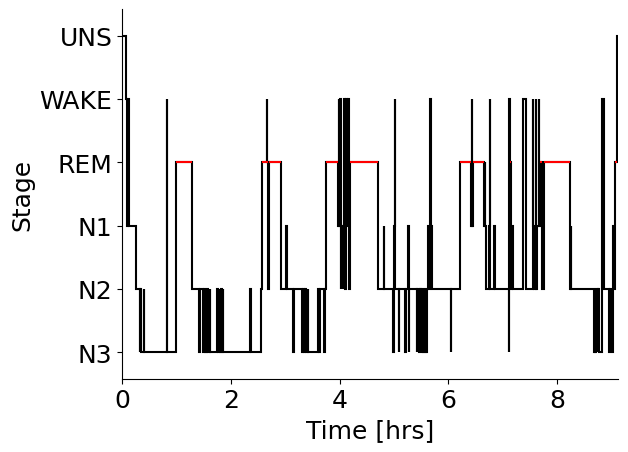

In [8]:
## visually inspect first row hypnogram
## DXA_001 9TIB condition == 9.12 hours worth of hypnogram sleep data
hyp, raw_codes = load_hypno(manifest.iloc[0]["hyp_path"])
print(manifest.iloc[0][["subject_id", "condition"]].to_dict())
print(len(hyp), "epochs ->", round(len(hyp) * 0.5 / 60, 2), "hours")

hyp.sleep_statistics()        # dict of stats, durations in minutes
hyp.plot_hypnogram();         # quick visual check of the staging


{'subject_id': 'DXA_001', 'condition': 'normal'}
1118 epochs -> 9.32 hours


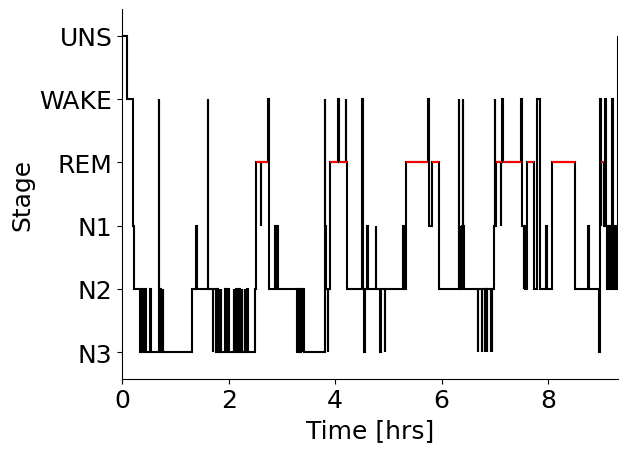

In [9]:
## visually inspect second row hypnogram data
## DXA_001 'normal' sleep condition, 9.32 hours of hypnogram data recorded
hyp, raw_codes = load_hypno(manifest.iloc[1]["hyp_path"])
print(manifest.iloc[1][["subject_id", "condition"]].to_dict())
print(len(hyp), "epochs ->", round(len(hyp) * 0.5 / 60, 2), "hours")

hyp.sleep_statistics()        # dict of stats, durations in minutes
hyp.plot_hypnogram();         # quick visual check of the staging

# Sleep Statistics

In [10]:
rows = []
for r in manifest.itertuples():
    df = pd.read_csv(r.hyp_path, encoding="utf-8-sig")
    df.columns = df.columns.str.strip()
    rows.append({
        "subject_id": r.subject_id,
        "condition": r.condition,
        "file": Path(r.hyp_path).name,
        "n_rows": len(df),
        "hours": round(len(df) * 0.5 / 60, 2),
        "study_date": df["StudyDate"].iloc[0],
        "night": df["Night"].iloc[0],
        "start_clock": df["ClockTime"].iloc[0],
        "end_clock": df["ClockTime"].iloc[-1],
    })

length_check = pd.DataFrame(rows)
display(length_check)
print(length_check.groupby("condition")["n_rows"].describe())

,subject_id,condition,file,n_rows,hours,study_date,night,start_clock,end_clock
0,DXA_001,9TIB,DXA_001_9TIB.csv,1095,9.12,07 Oct 2019,1,23:08:18,08:15:18
1,DXA_001,normal,DXA_001_normal.csv,1118,9.32,26 Sep 2019,1,22:41:54,08:00:24
2,DXA_002,9TIB,DXA_002_9TIB.csv,1088,9.07,29 Sep 2019,1,01:56:49,11:00:19
3,DXA_002,normal,DXA_002_normal.csv,865,7.21,26 Sep 2019,1,02:17:07,09:29:07
4,DXA_003,9TIB,DXA_003_9TIB.csv,812,6.77,05 Oct 2019,1,01:21:28,08:06:58
5,DXA_003,normal,DXA_003_normal.csv,599,4.99,28 Sep 2019,1,02:11:59,07:10:59
6,DXA_004,9TIB,DXA_004_9TIB.csv,1119,9.32,09 Oct 2019,1,23:30:46,08:49:46
7,DXA_004,normal,DXA_004_normal.csv,697,5.81,04 Oct 2019,1,01:11:58,06:59:58
8,DXA_005,9TIB,DXA_005_9TIB.csv,1083,9.03,09 Oct 2019,1,23:29:57,08:30:57
9,DXA_005,normal,DXA_005_normal.csv,928,7.73,03 Oct 2019,1,00:43:44,08:28:01


           count    mean         std    min     25%     50%     75%     max
condition                                                                  
9TIB         5.0  1039.4  127.868292  812.0  1083.0  1088.0  1095.0  1119.0
normal       5.0   841.4  202.591461  599.0   697.0   865.0   928.0  1118.0


In [11]:
rows, failed = [], []
for r in manifest.itertuples():
    try:
        hyp, raw_codes = load_hypno(r.hyp_path)
        stats = hyp.sleep_statistics()

        counts = raw_codes.map(STAGE_MAP).value_counts()
        raw_counts = {f"n_{lab}_epochs": int(counts.get(lab, 0)) for lab in STAGE_MAP.values()}

        rows.append({"subject_id": r.subject_id, "condition": r.condition,
                     "n_epochs": len(hyp), **stats, **raw_counts})
    except Exception as e:
        failed.append((r.subject_id, r.condition, repr(e)))

sleep_statistics_df = pd.DataFrame(rows)
sleep_statistics_df["condition"] = pd.Categorical(
sleep_statistics_df["condition"], categories=["normal", "9TIB"])
sleep_statistics_df = (sleep_statistics_df.sort_values(["subject_id", "condition"]).reset_index(drop=True))

print(f"{len(sleep_statistics_df)} nights processed, {len(failed)} failed")
for f in failed:
    print(f)

10 nights processed, 0 failed


In [12]:
sleep_statistics_df.head()

,subject_id,condition,n_epochs,TIB,SPT,WASO,TST,SE,SME,SFI,...,%N1,%N2,%N3,%REM,n_WAKE_epochs,n_N1_epochs,n_N2_epochs,n_N3_epochs,n_REM_epochs,n_UNS_epochs
0,DXA_001,normal,1118,559.0,546.5,13.0,533.5,95.4383,97.6212,0.9560,...,4.9672,48.9222,21.9306,24.1799,38,53,522,234,258,13
1,DXA_001,9TIB,1095,547.5,541.0,14.5,526.5,96.1644,97.3198,1.0256,...,5.8879,43.2099,24.1216,26.7806,30,62,455,254,282,12
2,DXA_002,normal,865,432.5,400.0,27.0,371.0,85.7803,92.7500,2.6685,...,8.8949,31.2668,43.6658,16.1725,69,66,232,324,120,54
3,DXA_002,9TIB,1088,544.0,473.0,35.5,435.0,79.9632,91.9662,2.4138,...,4.0230,20.8046,50.5747,24.5977,79,35,181,440,214,139
4,DXA_003,normal,599,299.5,260.0,9.5,250.5,83.6394,96.3462,1.3174,...,5.3892,26.9461,40.7186,26.9461,20,27,135,204,135,78


In [13]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.width", 200)
sleep_statistics_df.head()

,subject_id,condition,n_epochs,TIB,SPT,WASO,TST,SE,SME,SFI,SOL,SOL_5min,Lat_REM,WAKE,N1,N2,N3,REM,UNS,%N1,%N2,%N3,%REM,n_WAKE_epochs,n_N1_epochs,n_N2_epochs,n_N3_epochs,n_REM_epochs,n_UNS_epochs
0,DXA_001,normal,1118,559.0,546.5,13.0,533.5,95.4383,97.6212,0.9560,12.0,12.0,150.5,19.0,26.5,261.0,117.0,129.0,6.5,4.9672,48.9222,21.9306,24.1799,38,53,522,234,258,13
1,DXA_001,9TIB,1095,547.5,541.0,14.5,526.5,96.1644,97.3198,1.0256,5.0,8.0,59.5,15.0,31.0,227.5,127.0,141.0,6.0,5.8879,43.2099,24.1216,26.7806,30,62,455,254,282,12
2,DXA_002,normal,865,432.5,400.0,27.0,371.0,85.7803,92.7500,2.6685,22.0,22.0,119.5,34.5,33.0,116.0,162.0,60.0,27.0,8.8949,31.2668,43.6658,16.1725,69,66,232,324,120,54
3,DXA_002,9TIB,1088,544.0,473.0,35.5,435.0,79.9632,91.9662,2.4138,11.5,11.5,115.5,39.5,17.5,90.5,220.0,107.0,69.5,4.0230,20.8046,50.5747,24.5977,79,35,181,440,214,139
4,DXA_003,normal,599,299.5,260.0,9.5,250.5,83.6394,96.3462,1.3174,14.5,14.5,50.0,10.0,13.5,67.5,102.0,67.5,39.0,5.3892,26.9461,40.7186,26.9461,20,27,135,204,135,78


In [14]:
sleep_statistics_df.groupby('condition', as_index=True, observed=True)[['TIB', 'SPT','TST', 'WASO', 'SE','SOL','Lat_REM','SME', 'SFI']].describe().round(2).T

# display(sleep_descriptives_df)

condition      normal    9TIB
TIB     count    5.00    5.00
        mean   420.70  519.70
        std    101.30   63.93
        min    299.50  406.00
        25%    348.50  541.50
        50%    432.50  544.00
        75%    464.00  547.50
        max    559.00  559.50
SPT     count    5.00    5.00
        mean   398.70  491.90
        std    109.39   60.12
        min    260.00  398.50
        25%    335.50  473.00
        50%    400.00  501.50
        75%    451.50  541.00
        max    546.50  545.50
TST     count    5.00    5.00
        mean   379.80  465.00
        std    105.37   55.62
        min    250.50  385.50
        25%    328.00  435.00
        50%    371.00  478.50
        75%    416.00  499.50
        max    533.50  526.50
WASO    count    5.00    5.00
        mean    16.40   26.20
        std      9.26   14.21
        min      7.00   13.00
        25%      9.50   14.50
        50%     13.00   22.00
        75%     25.50   35.50
        max     27.00   46.00
SE      count    5.00    5.00
        mean    89.73   89.74
        std      5.11    6.44
        min     83.64   79.96
        25%     85.78   88.37
        50%     89.66   89.28
        75%     94.12   94.95
        max     95.44   96.16
SOL     count    5.00    5.00
        mean    13.60   10.40
        std      5.09    8.70
        min      9.50    3.50
        25%     10.00    5.00
        50%     12.00    7.00
        75%     14.50   11.50
        max     22.00   25.00
Lat_REM count    5.00    5.00
        mean   105.00  146.60
        std     46.80  128.37
        min     50.00   59.50
        25%     61.00   76.50
        50%    119.50  109.00
        75%    144.00  115.50
        max    150.50  372.50
SME     count    5.00    5.00
        mean    95.32   94.60
        std      2.70    2.68
        min     92.14   91.57
        25%     92.75   91.97
        50%     96.35   95.41
        75%     97.62   96.74
        max     97.76   97.32
SFI     count    5.00    5.00
        mean     1.59    1.79
        std      0.80    0.51
        min      0.82    1.03
        25%      0.96    1.69
        50%      1.32    1.79
        75%      2.16    2.04
        max      2.67    2.41

# Sleep Spindles

In [19]:
EEG_CH = "EEG4"
INCLUDE = (2, 3)                                  # YASA int codes: 2 = N2, 3 = N3
STAGE_NAMES = {1: "N1", 2: "N2", 3: "N3", 4: "REM"}
EPOCH_SEC = 30

def load_eeg(edf_path, ch=EEG_CH):
    raw = mne.io.read_raw_edf(edf_path, preload=True, verbose="ERROR")
    if ch not in raw.ch_names:
        raise KeyError(f"{ch} not in EDF channels: {raw.ch_names}")
    raw.pick([ch])
    return raw

def hypno_to_samples(hyp, n_samples, sf):
    """Stretch the 30 s hypnogram to one value per EEG sample (YASA int codes)."""
    h = hyp.as_int().to_numpy()
    up = np.repeat(h, int(round(EPOCH_SEC * sf)))
    if len(up) >= n_samples:
        return up[:n_samples]
    return np.pad(up, (0, n_samples - len(up)), constant_values=-2)   # pad with 'unscored'

def tag(df, subject_id, condition):
    df = df.reset_index(drop=True).copy()
    df.insert(0, "condition", condition)
    df.insert(0, "subject_id", subject_id)
    return df

def detect_spindles_night(edf_path, hyp, subject_id, condition):
    raw = load_eeg(edf_path)
    sf = raw.info["sfreq"]
    data = raw.get_data(units="uV")                       # shape (1, n_samples), in microvolts
    hyp_up = hypno_to_samples(hyp, data.shape[1], sf)

    sp = yasa.spindles_detect(data, sf, ch_names=[EEG_CH], hypno=hyp_up,
                              include=INCLUDE, verbose=False)

    if sp is None:                                        # YASA returns None if nothing detected
        events, by_stage = pd.DataFrame(), pd.DataFrame()
    else:
        events = sp.summary()
        by_stage = sp.summary(grp_chan=True, grp_stage=True).reset_index()
        for df in (events, by_stage):
            df["Stage"] = df["Stage"].map(STAGE_NAMES)

    meta = {"subject_id": subject_id, "condition": condition, "sf": sf,
            "edf_start": raw.info["meas_date"],
            "edf_min": round(data.shape[1] / sf / 60, 2),
            "hypno_min": round(len(hyp) * EPOCH_SEC / 60, 2),
            "n_spindles": len(events)}
    return tag(events, subject_id, condition), tag(by_stage, subject_id, condition), meta

In [20]:
events_list, stage_list, meta_list, failed = [], [], [], []

for r in manifest.itertuples():
    try:
        hyp, _ = load_hypno(r.hyp_path)
        events, by_stage, meta = detect_spindles_night(r.edf_path, hyp, r.subject_id, r.condition)
        events_list.append(events); stage_list.append(by_stage); meta_list.append(meta)
    except Exception as e:
        failed.append((r.subject_id, r.condition, repr(e)))

print(f"{len(meta_list)} nights processed, {len(failed)} failed")
for f in failed[:10]:
    print(f)

if meta_list:
    spindle_events_df   = pd.concat(events_list, ignore_index=True)   # one row per spindle
    spindle_by_stage_df = pd.concat(stage_list, ignore_index=True)    # one row per night x stage
    spindle_meta_df     = pd.DataFrame(meta_list)

    for df in (spindle_events_df, spindle_by_stage_df, spindle_meta_df):
        df["condition"] = pd.Categorical(df["condition"], categories=["normal", "9TIB"])

[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.2s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]

10 nights processed, 0 failed


In [ ]:
# spindle_events_df.shape

NameError: name 'spindle_events_df' is not defined

In [18]:
spindle_events_df.head()

NameError: name 'spindle_events_df' is not defined

In [ ]:
spindle_by_stage_df.shape

(20, 15)

In [ ]:
spindle_by_stage_df.round(2).head(20)

,subject_id,condition,Stage,Channel,Count,Density,Duration,Amplitude,AmpFiltered,RMS,AbsPower,RelPower,Frequency,Oscillations,Symmetry
0,DXA_001,9TIB,N2,EEG4,816,3.59,0.82,31.29,19.01,6.73,1.60,0.39,12.68,10.01,0.51
1,DXA_001,9TIB,N3,EEG4,56,0.44,0.71,34.67,20.56,7.58,1.74,0.36,12.60,8.61,0.50
2,DXA_001,normal,N2,EEG4,990,3.79,0.81,32.06,19.97,6.92,1.64,0.41,12.77,10.04,0.52
3,DXA_001,normal,N3,EEG4,96,0.82,0.75,36.48,21.75,8.07,1.77,0.35,12.60,9.07,0.52
4,DXA_002,9TIB,N2,EEG4,31,0.34,0.73,39.01,23.35,8.84,1.87,0.33,12.33,8.87,0.52
5,DXA_002,9TIB,N3,EEG4,13,0.06,0.65,46.39,26.76,10.43,1.96,0.29,12.20,7.62,0.61
6,DXA_002,normal,N2,EEG4,71,0.61,0.78,37.30,22.09,8.27,1.74,0.32,12.35,9.30,0.53
7,DXA_002,normal,N3,EEG4,18,0.11,0.73,42.62,25.58,9.48,1.91,0.33,12.31,8.56,0.50
8,DXA_003,9TIB,N2,EEG4,59,0.32,0.72,30.81,18.71,6.90,1.63,0.34,12.48,8.75,0.47
9,DXA_003,9TIB,N3,EEG4,13,0.10,0.63,38.76,22.61,8.76,1.84,0.31,12.65,7.54,0.49


In [ ]:
spindle_meta_df.shape

(10, 7)

In [ ]:
## EDF length vs hypnogram length, spindle counts per night
spindle_meta_df

,subject_id,condition,sf,edf_start,edf_min,hypno_min,n_spindles
0,DXA_001,9TIB,256.0,2000-01-01 00:00:00+00:00,548.48,547.5,872
1,DXA_001,normal,256.0,2000-01-01 00:00:00+00:00,559.55,559.0,1086
2,DXA_002,9TIB,256.0,2000-01-01 00:00:00+00:00,544.58,544.0,44
3,DXA_002,normal,256.0,2000-01-01 00:00:00+00:00,433.28,432.5,89
4,DXA_003,9TIB,256.0,2000-01-01 00:00:00+00:00,407.10,406.0,72
5,DXA_003,normal,256.0,2000-01-01 00:00:00+00:00,300.38,299.5,76
6,DXA_004,9TIB,256.0,2000-01-01 00:00:00+00:00,560.87,559.5,370
7,DXA_004,normal,256.0,2000-01-01 00:00:00+00:00,349.40,348.5,151
8,DXA_005,9TIB,256.0,2000-01-01 00:00:00+00:00,542.27,541.5,250
9,DXA_005,normal,256.0,2000-01-01 00:00:00+00:00,465.37,464.0,102


In [ ]:
## Spindle count per night and stage, and a quick condition comparison
print(spindle_events_df.groupby(["subject_id", "condition", "Stage"], observed=True).size())
print(spindle_by_stage_df.groupby(["condition", "Stage"], observed=True)[["Density", "Duration", "Frequency"]].mean().round(2))

subject_id  condition  Stage
DXA_001     normal     N2       990
                       N3        96
            9TIB       N2       816
                       N3        56
DXA_002     normal     N2        71
                       N3        18
            9TIB       N2        31
                       N3        13
DXA_003     normal     N2        63
                       N3        13
            9TIB       N2        59
                       N3        13
DXA_004     normal     N2       146
                       N3         5
            9TIB       N2       360
                       N3        10
DXA_005     normal     N2        72
                       N3        30
            9TIB       N2       179
                       N3        71
dtype: int64
                 Density  Duration  Frequency
condition Stage                              
normal    N2        1.42      0.75      12.63
          N3        0.25      0.71      12.59
9TIB      N2        1.43      0.75      12.52
        

# Stop

In [ ]:
stop 
## stop

NameError: name 'stop' is not defined